# Exploratory Data Analysis

## Setup

In [ ]:
import os

FIG_DIR = './Plots'   # figures are saved here
os.makedirs(FIG_DIR, exist_ok=True)

In [ ]:
import subprocess, os

if not os.path.exists('dontpatronizeme'):
    subprocess.run(['git', 'clone',
                    'https://github.com/Perez-AlmendrosC/dontpatronizeme.git'], check=True)
if not os.path.exists('NLPLabs-2024'):
    subprocess.run(['git', 'clone',
                    'https://github.com/CRLala/NLPLabs-2024.git'], check=True)

In [ ]:
import ast, re, html, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import nltk
import spacy
import torch
from collections import Counter
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE
from wordcloud import WordCloud
from transformers import AutoTokenizer, AutoModel
import umap

warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
from nltk.corpus import stopwords

STOP_WORDS = set(stopwords.words('english'))
C_NO   = '#4878CF'
C_PCL  = '#D65F5F'
PALETTE = {'No PCL': C_NO, 'PCL': C_PCL}
os.makedirs(FIG_DIR, exist_ok=True)

## Data Loading

In [ ]:
PCL_TSV     = 'NLPLabs-2024/Dont_Patronize_Me_Trainingset/dontpatronizeme_pcl.tsv'
CAT_TSV     = 'NLPLabs-2024/Dont_Patronize_Me_Trainingset/dontpatronizeme_categories.tsv'
TRAIN_SPLIT = 'dontpatronizeme/semeval-2022/practice splits/train_semeval_parids-labels.csv'
DEV_SPLIT   = 'dontpatronizeme/semeval-2022/practice splits/dev_semeval_parids-labels.csv'

df_raw = pd.read_csv(
    PCL_TSV, sep='\t', skiprows=4, header=None,
    names=['par_id','art_id','keyword','country_code','text','label'],
    quoting=3
)
df_raw.dropna(subset=['text'], inplace=True)
df_raw['label'] = pd.to_numeric(df_raw['label'], errors='coerce')
df_raw.dropna(subset=['label'], inplace=True)
df_raw['label'] = df_raw['label'].astype(int)
df_raw['label_binary'] = (df_raw['label'] >= 2).astype(int)
print(f'Full corpus: {len(df_raw):,} rows | PCL: {df_raw["label_binary"].sum():,} | No PCL: {(df_raw["label_binary"]==0).sum():,}')

def list_to_binary(val):
    try:
        return 1 if any(ast.literal_eval(str(val))) else 0
    except:
        return 0

train_ids = pd.read_csv(TRAIN_SPLIT)
dev_ids   = pd.read_csv(DEV_SPLIT)
train_ids['label_binary'] = train_ids['label'].apply(list_to_binary)
dev_ids['label_binary']   = dev_ids['label'].apply(list_to_binary)

df_train = train_ids[['par_id','label_binary']].merge(
    df_raw[['par_id','art_id','keyword','country_code','text','label']],
    on='par_id', how='left'
)
df_dev = dev_ids[['par_id','label_binary']].merge(
    df_raw[['par_id','art_id','keyword','country_code','text','label']],
    on='par_id', how='left'
)
print(f'Train: {len(df_train):,} | PCL: {df_train["label_binary"].sum():,} ({df_train["label_binary"].mean()*100:.1f}%)')
print(f'Dev:   {len(df_dev):,}   | PCL: {df_dev["label_binary"].sum():,} ({df_dev["label_binary"].mean()*100:.1f}%)')

# categories file: text column is at position 3
df_cat = pd.read_csv(
    CAT_TSV, sep='\t', skiprows=4, header=None,
    names=['par_id','art_id','text','keyword','country_code',
           'span_start','span_end','span_text','category','n_annotators'],
    quoting=3
)
print(f'Categories: {len(df_cat):,} annotated spans')

df_train['label_str'] = df_train['label_binary'].map({0: 'No PCL', 1: 'PCL'})
df_dev['label_str']   = df_dev['label_binary'].map({0: 'No PCL', 1: 'PCL'})

Full corpus: 10,468 rows | PCL: 993 | No PCL: 9,475
Train: 8,375 | PCL: 794 (9.5%)
Dev:   2,094   | PCL: 199 (9.5%)
Categories: 2,760 annotated spans


## EDA 1: Class Distribution and Label Imbalance

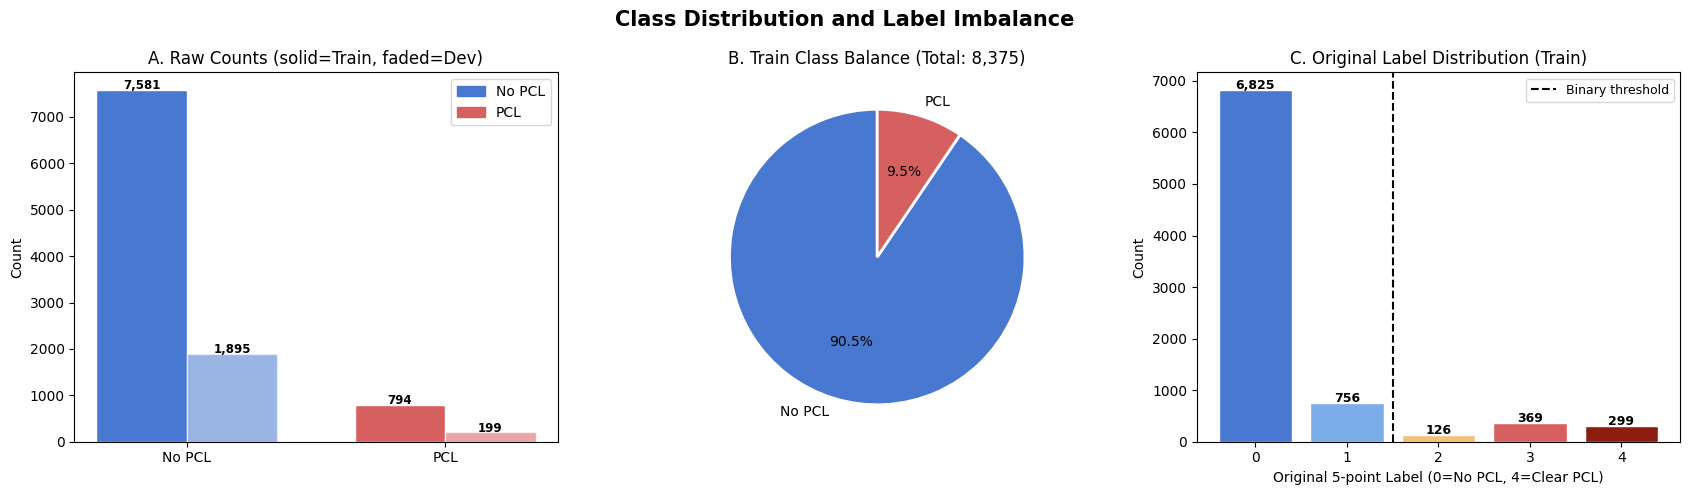

Imbalance ratio (No PCL : PCL) = 9.5 : 1
Majority-class accuracy baseline = 90.5%


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Class Distribution and Label Imbalance', fontsize=15, fontweight='bold')

ax = axes[0]
splits = {'Train': df_train, 'Dev': df_dev}
x = np.arange(2); w = 0.35
for i, (split_name, df_s) in enumerate(splits.items()):
    counts = [(df_s['label_binary']==0).sum(), (df_s['label_binary']==1).sum()]
    offset = -w/2 if i == 0 else w/2
    bars = ax.bar(x + offset, counts, w, color=[C_NO, C_PCL],
                  alpha=1.0 if i==0 else 0.55, label=split_name, edgecolor='white')
    for bar, val in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{val:,}', ha='center', fontsize=8.5, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(['No PCL', 'PCL'])
ax.set_ylabel('Count')
ax.set_title('A. Raw Counts (solid=Train, faded=Dev)')
ax.legend(handles=[mpatches.Patch(color=C_NO, label='No PCL'),
                   mpatches.Patch(color=C_PCL, label='PCL')])

ax = axes[1]
n_pcl = (df_train['label_binary']==1).sum()
n_no  = (df_train['label_binary']==0).sum()
ax.pie([n_no, n_pcl], labels=['No PCL', 'PCL'], colors=[C_NO, C_PCL],
       autopct='%1.1f%%', startangle=90,
       wedgeprops=dict(linewidth=2, edgecolor='white'))
ax.set_title(f'B. Train Class Balance (Total: {len(df_train):,})')

ax = axes[2]
label_counts = df_train['label'].value_counts().sort_index()
colours_5 = [C_NO, '#7baee8', '#f5c07a', C_PCL, '#8b1e10']
bars = ax.bar([str(l) for l in label_counts.index], label_counts.values,
              color=colours_5, edgecolor='white')
for bar, val in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f'{val:,}', ha='center', fontsize=9, fontweight='bold')
ax.axvline(x=1.5, color='black', linestyle='--', linewidth=1.5, label='Binary threshold')
ax.set_xlabel('Original 5-point Label (0=No PCL, 4=Clear PCL)')
ax.set_ylabel('Count')
ax.set_title('C. Original Label Distribution (Train)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda1_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Imbalance ratio (No PCL : PCL) = {n_no/n_pcl:.1f} : 1')
print(f'Majority-class accuracy baseline = {100*n_no/(n_no+n_pcl):.1f}%')

## EDA 2: Token Length Distribution by Class

           Min  Mean  Median  75th pct    Max
label_str                                    
No PCL     1.0  48.2    42.0      59.0  909.0
PCL        6.0  53.5    47.0      66.0  512.0


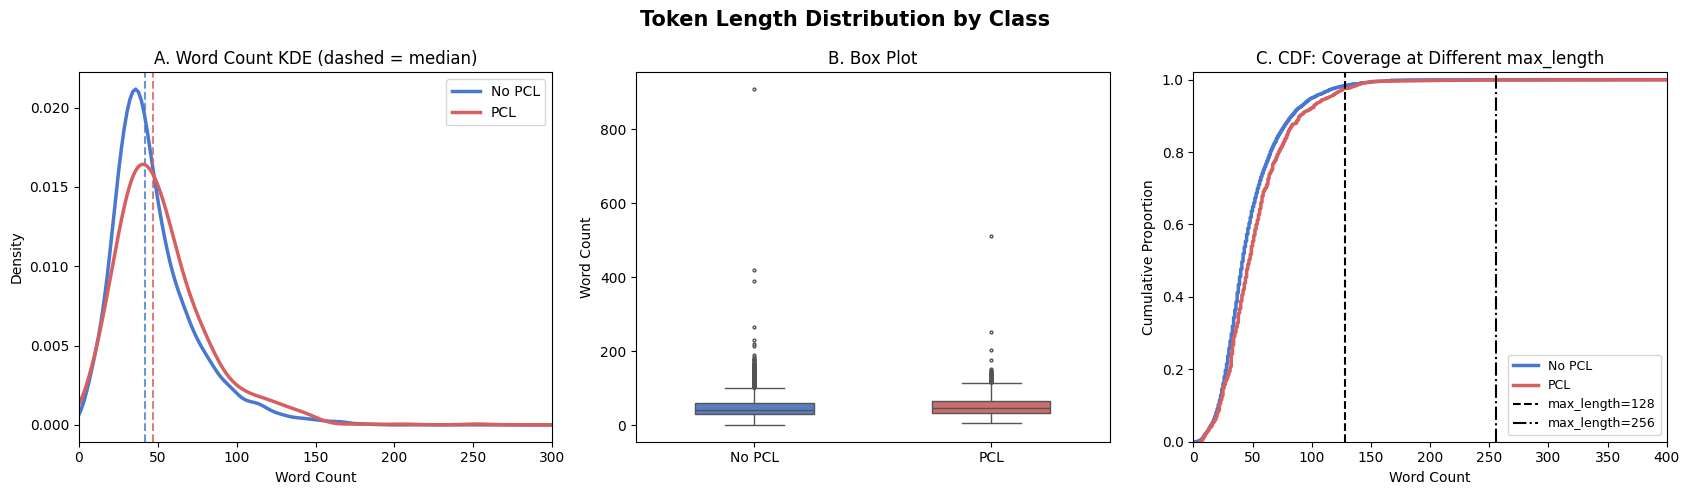

In [ ]:
df_train['n_words'] = df_train['text'].str.split().str.len()

summary = df_train.groupby('label_str')['n_words'].describe()[['min','mean','50%','75%','max']]
summary.columns = ['Min','Mean','Median','75th pct','Max']
print(summary.round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Token Length Distribution by Class', fontsize=15, fontweight='bold')

ax = axes[0]
for cls, grp in df_train.groupby('label_str'):
    grp['n_words'].plot.kde(ax=ax, label=cls, color=PALETTE[cls], linewidth=2.5)
    ax.axvline(grp['n_words'].median(), color=PALETTE[cls], linestyle='--', linewidth=1.5, alpha=0.8)
ax.set_xlim(0, 300)
ax.set_xlabel('Word Count'); ax.set_ylabel('Density')
ax.set_title('A. Word Count KDE (dashed = median)')
ax.legend()

ax = axes[1]
sns.boxplot(data=df_train, x='label_str', y='n_words',
            order=['No PCL','PCL'], hue='label_str', palette=PALETTE,
            width=0.5, fliersize=2, ax=ax, legend=False)
ax.set_xlabel(''); ax.set_ylabel('Word Count')
ax.set_title('B. Box Plot')

ax = axes[2]
for cls, grp in df_train.groupby('label_str'):
    s = np.sort(grp['n_words'].values)
    ax.plot(s, np.arange(1, len(s)+1)/len(s), label=cls, color=PALETTE[cls], linewidth=2.5)
for thresh, ls, lbl in [(128,'--','max_length=128'), (256,'-.','max_length=256')]:
    ax.axvline(thresh, color='black', linestyle=ls, linewidth=1.5, label=lbl)
ax.set_xlim(0, 400); ax.set_ylim(0, 1.02)
ax.set_xlabel('Word Count'); ax.set_ylabel('Cumulative Proportion')
ax.set_title('C. CDF: Coverage at Different max_length')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda2_token_length.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 3: Vocabulary Size and Lexical Diversity

Total tokens:      407,655
Unique tokens:     29,966
Lexical diversity: 7.35%
No PCL   | vocab=28,406  diversity=7.78%
PCL      | vocab=7,044  diversity=16.58%


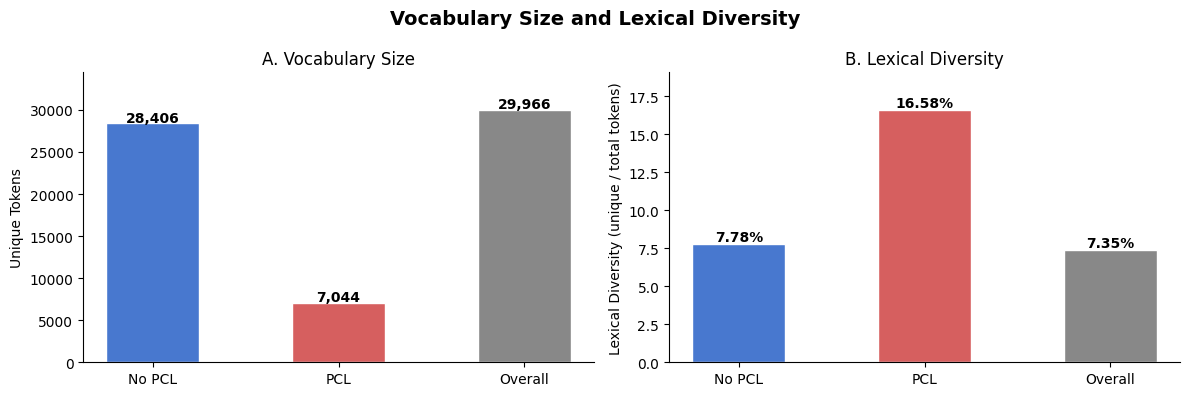

In [ ]:
all_tokens    = [w for text in df_train['text'] for w in str(text).lower().split()]
unique_tokens = set(all_tokens)

vocab_stats = {}
for cls, label in [(0, 'No PCL'), (1, 'PCL')]:
    toks = [w for text in df_train[df_train['label_binary']==cls]['text']
            for w in str(text).lower().split()]
    vocab_stats[label] = {'total': len(toks), 'unique': len(set(toks)),
                          'diversity': len(set(toks))/len(toks)*100}

print(f'Total tokens:      {len(all_tokens):,}')
print(f'Unique tokens:     {len(unique_tokens):,}')
print(f'Lexical diversity: {len(unique_tokens)/len(all_tokens)*100:.2f}%')
for label, s in vocab_stats.items():
    print(f'{label:8} | vocab={s["unique"]:,}  diversity={s["diversity"]:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Vocabulary Size and Lexical Diversity', fontsize=14, fontweight='bold')

labels_v = ['No PCL', 'PCL', 'Overall']
vocab_sizes = [vocab_stats['No PCL']['unique'], vocab_stats['PCL']['unique'], len(unique_tokens)]
colours_v   = [C_NO, C_PCL, '#888888']
bars = axes[0].bar(labels_v, vocab_sizes, color=colours_v, edgecolor='white', width=0.5)
for bar, val in zip(bars, vocab_sizes):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}', ha='center', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Unique Tokens'); axes[0].set_title('A. Vocabulary Size')
axes[0].set_ylim(0, max(vocab_sizes) * 1.15)

diversities = [vocab_stats['No PCL']['diversity'], vocab_stats['PCL']['diversity'],
               len(unique_tokens)/len(all_tokens)*100]
bars = axes[1].bar(labels_v, diversities, color=colours_v, edgecolor='white', width=0.5)
for bar, val in zip(bars, diversities):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f'{val:.2f}%', ha='center', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Lexical Diversity (unique / total tokens)')
axes[1].set_title('B. Lexical Diversity')
axes[1].set_ylim(0, max(diversities) * 1.15)

sns.despine(); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/vocabulary_diversity.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 4: Top N-grams by Class (Bigrams and Trigrams)

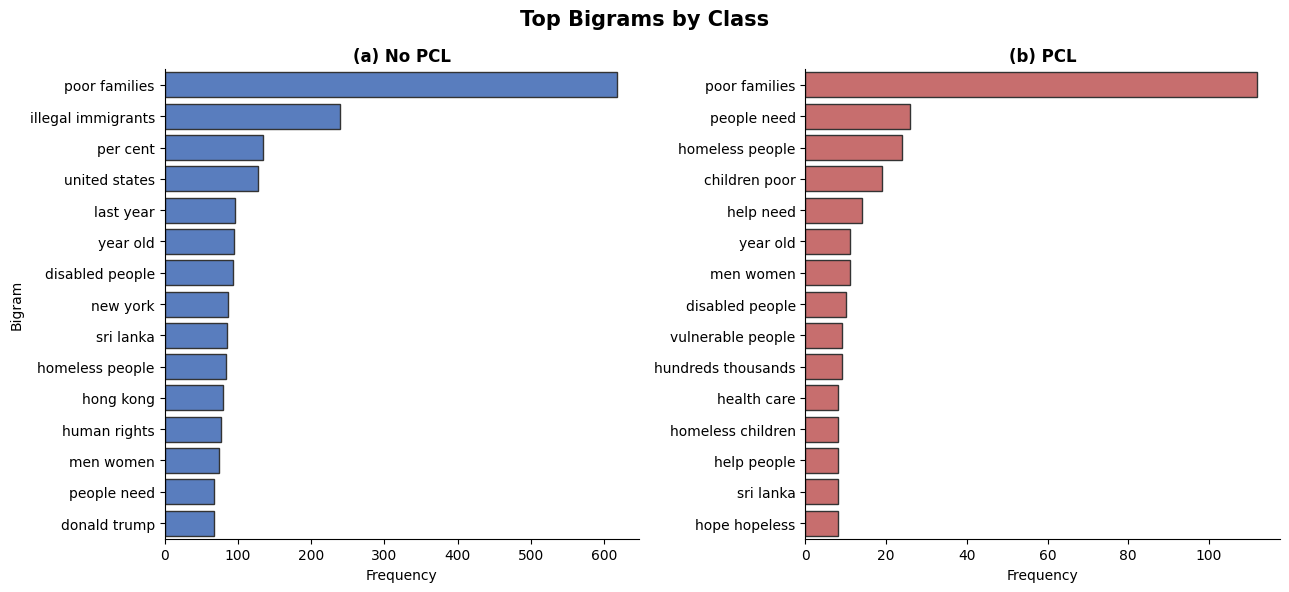

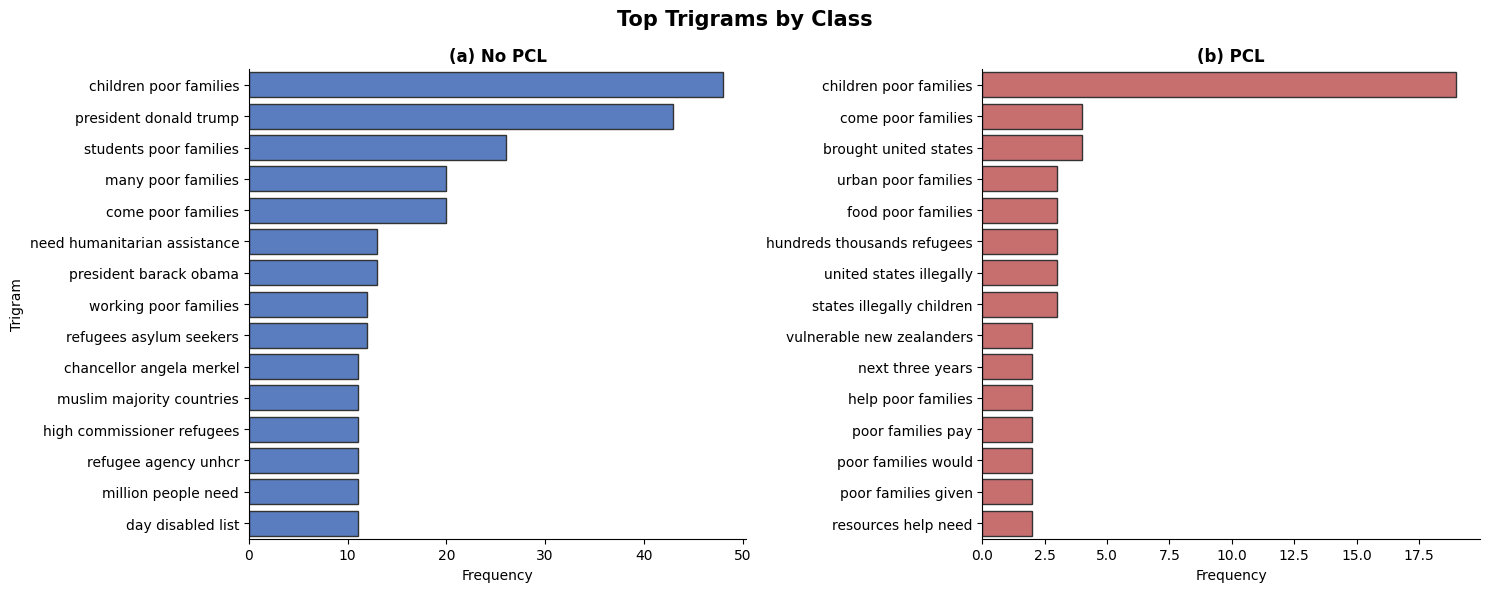

In [ ]:
stop_words_list = list(STOP_WORDS)

def get_top_ngrams(corpus, n=2, top_k=15):
    vec = CountVectorizer(ngram_range=(n, n), stop_words=stop_words_list,
                          token_pattern=r'\b[a-zA-Z]{3,}\b').fit(corpus)
    bag  = vec.transform(corpus)
    freq = [(word, bag.sum(axis=0)[0, idx]) for word, idx in vec.vocabulary_.items()]
    return sorted(freq, key=lambda x: x[1], reverse=True)[:top_k]

pcl_text    = df_train[df_train['label_binary']==1]['text'].astype(str)
no_pcl_text = df_train[df_train['label_binary']==0]['text'].astype(str)

top_pcl_bigrams    = get_top_ngrams(pcl_text,    n=2)
top_no_pcl_bigrams = get_top_ngrams(no_pcl_text, n=2)
top_pcl_trigrams   = get_top_ngrams(pcl_text,    n=3)
top_no_pcl_trigrams = get_top_ngrams(no_pcl_text, n=3)

# Bigrams
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Top Bigrams by Class', fontsize=15, fontweight='bold')
sns.barplot(ax=axes[0], x='Frequency', y='Bigram',
            data=pd.DataFrame(top_no_pcl_bigrams, columns=['Bigram','Frequency']),
            color=C_NO, edgecolor='.2')
axes[0].set_title('(a) No PCL', fontweight='bold')
axes[0].set_xlabel('Frequency'); axes[0].set_ylabel('Bigram')
sns.barplot(ax=axes[1], x='Frequency', y='Bigram',
            data=pd.DataFrame(top_pcl_bigrams, columns=['Bigram','Frequency']),
            color=C_PCL, edgecolor='.2')
axes[1].set_title('(b) PCL', fontweight='bold')
axes[1].set_xlabel('Frequency'); axes[1].set_ylabel('')
sns.despine(); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda4a_bigrams.png', dpi=150, bbox_inches='tight')
plt.show()

# Trigrams
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Top Trigrams by Class', fontsize=15, fontweight='bold')
sns.barplot(ax=axes[0], x='Frequency', y='Trigram',
            data=pd.DataFrame(top_no_pcl_trigrams, columns=['Trigram','Frequency']),
            color=C_NO, edgecolor='.2')
axes[0].set_title('(a) No PCL', fontweight='bold')
axes[0].set_xlabel('Frequency'); axes[0].set_ylabel('Trigram')
sns.barplot(ax=axes[1], x='Frequency', y='Trigram',
            data=pd.DataFrame(top_pcl_trigrams, columns=['Trigram','Frequency']),
            color=C_PCL, edgecolor='.2')
axes[1].set_title('(b) PCL', fontweight='bold')
axes[1].set_xlabel('Frequency'); axes[1].set_ylabel('')
sns.despine(); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda4b_trigrams.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 5: Keyword and Country PCL Rate

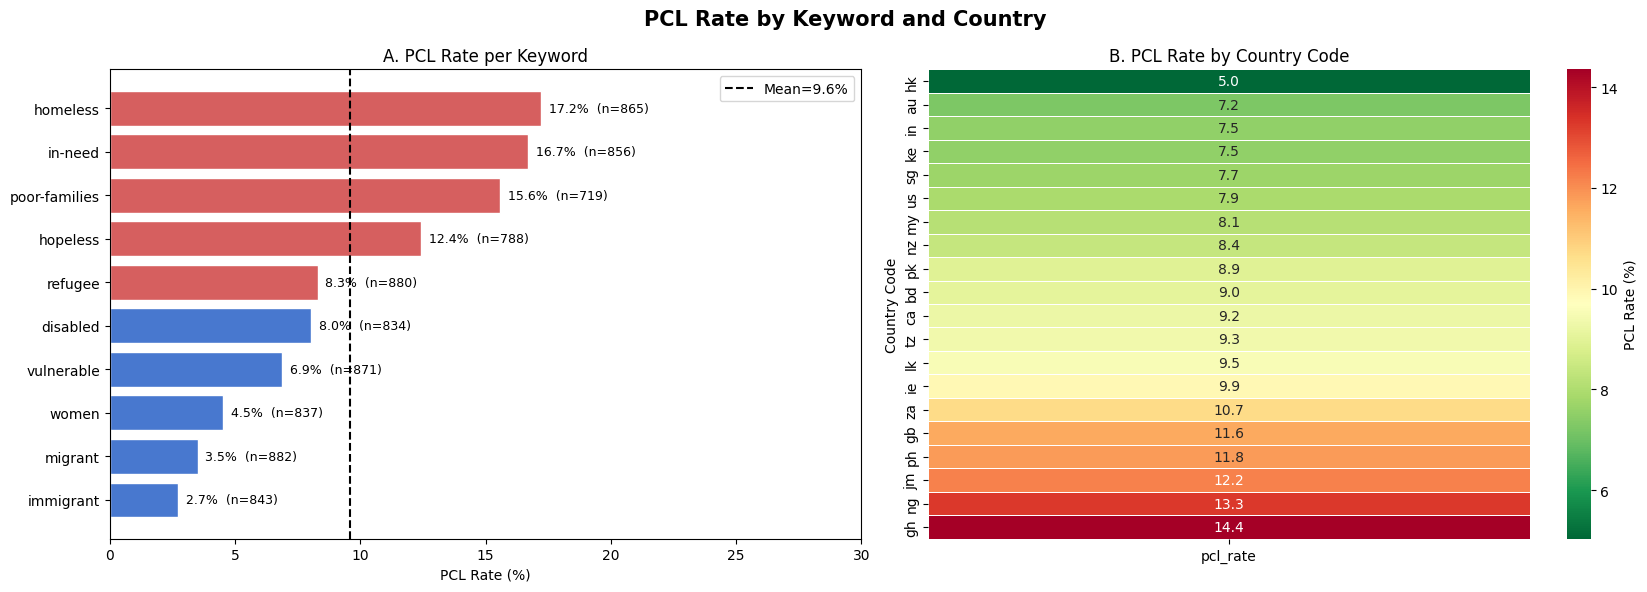

Highest PCL-rate keywords:
      keyword  pcl_rate  total
poor-families 15.577191    719
      in-need 16.705607    856
     homeless 17.225434    865

Lowest PCL-rate keywords:
  keyword  pcl_rate  total
immigrant  2.728351    843
  migrant  3.514739    882
    women  4.540024    837


In [ ]:
kw_stats = df_train.groupby('keyword').agg(
    total=('label_binary','count'), pcl=('label_binary','sum')
).reset_index()
kw_stats['pcl_rate'] = kw_stats['pcl'] / kw_stats['total'] * 100
kw_stats = kw_stats.sort_values('pcl_rate', ascending=True)

cc_stats = df_train.groupby('country_code').agg(
    total=('label_binary','count'), pcl=('label_binary','sum')
).reset_index()
cc_stats['pcl_rate'] = cc_stats['pcl'] / cc_stats['total'] * 100
cc_stats = cc_stats[cc_stats['total'] >= 50].sort_values('pcl_rate', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('PCL Rate by Keyword and Country', fontsize=15, fontweight='bold')

ax = axes[0]
med = kw_stats['pcl_rate'].median()
colours_kw = [C_PCL if r >= med else C_NO for r in kw_stats['pcl_rate']]
bars = ax.barh(kw_stats['keyword'], kw_stats['pcl_rate'], color=colours_kw, edgecolor='white')
for bar, val, tot in zip(bars, kw_stats['pcl_rate'], kw_stats['total']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%  (n={tot})', va='center', fontsize=9)
ax.axvline(kw_stats['pcl_rate'].mean(), color='black', linestyle='--', linewidth=1.5,
           label=f"Mean={kw_stats['pcl_rate'].mean():.1f}%")
ax.set_xlabel('PCL Rate (%)'); ax.set_title('A. PCL Rate per Keyword')
ax.legend(); ax.set_xlim(0, 30)

ax = axes[1]
sns.heatmap(cc_stats.set_index('country_code')[['pcl_rate']],
            annot=True, fmt='.1f', cmap='RdYlGn_r', linewidths=0.5,
            ax=ax, cbar_kws={'label': 'PCL Rate (%)'})
ax.set_title('B. PCL Rate by Country Code')
ax.set_ylabel('Country Code'); ax.set_xlabel('')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda5_keyword_country.png', dpi=150, bbox_inches='tight')
plt.show()

print('Highest PCL-rate keywords:')
print(kw_stats.tail(3)[['keyword','pcl_rate','total']].to_string(index=False))
print('\nLowest PCL-rate keywords:')
print(kw_stats.head(3)[['keyword','pcl_rate','total']].to_string(index=False))

## EDA 6: Discriminative N-grams via Log-Odds TF-IDF

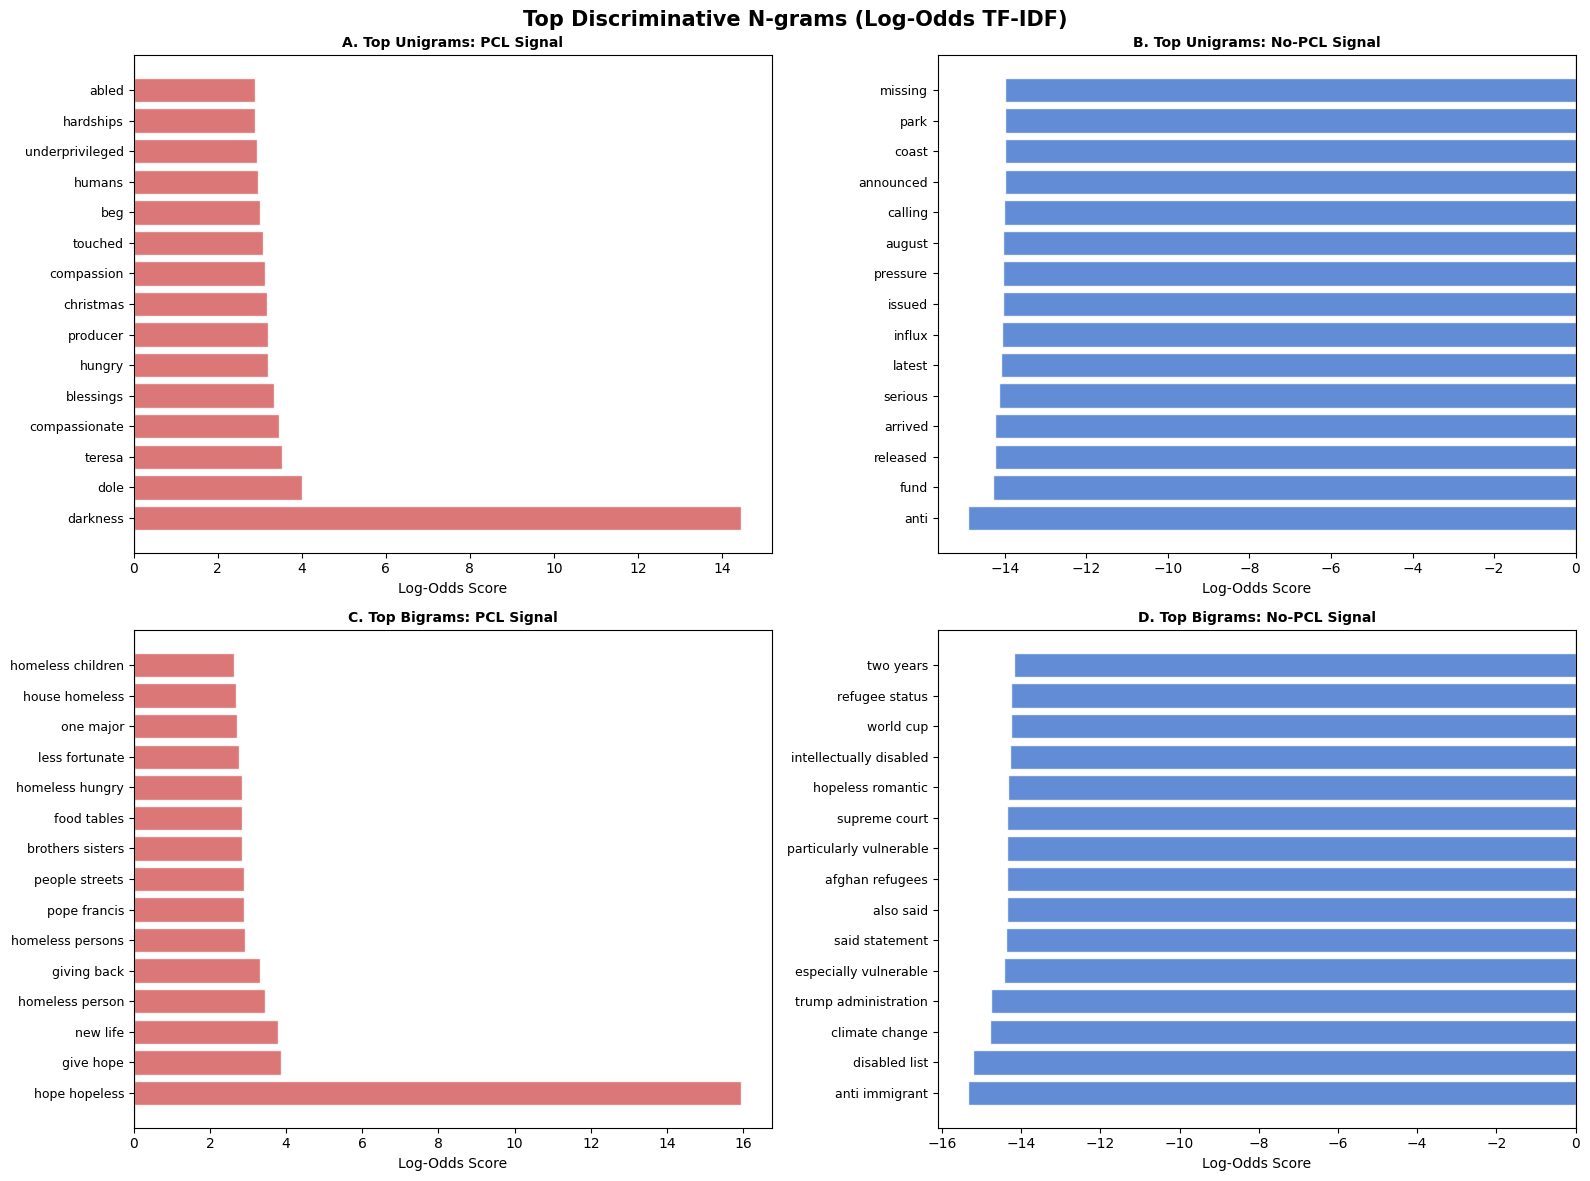

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return ' '.join(w for w in text.split() if w not in STOP_WORDS and len(w) > 2)

pcl_texts_clean = df_train[df_train['label_binary']==1]['text'].apply(clean_text).tolist()
no_texts_clean  = df_train[df_train['label_binary']==0]['text'].apply(clean_text).tolist()

def log_odds_ngrams(pos_texts, neg_texts, ngram_range, top_n=15):
    all_texts = pos_texts + neg_texts
    labels    = [1]*len(pos_texts) + [0]*len(neg_texts)
    vec = TfidfVectorizer(ngram_range=ngram_range, max_features=12000, min_df=5, sublinear_tf=True)
    X   = vec.fit_transform(all_texts).toarray()
    vocab = vec.get_feature_names_out()
    lab = np.array(labels)
    log_odds = np.log((X[lab==1].mean(axis=0) + 1e-9) / (X[lab==0].mean(axis=0) + 1e-9))
    top_pos = np.argsort(log_odds)[-top_n:][::-1]
    top_neg = np.argsort(log_odds)[:top_n]
    return ([(vocab[i], log_odds[i]) for i in top_pos],
            [(vocab[i], log_odds[i]) for i in top_neg])

top_pcl_uni, top_no_uni = log_odds_ngrams(pcl_texts_clean, no_texts_clean, (1,1))
top_pcl_bi,  top_no_bi  = log_odds_ngrams(pcl_texts_clean, no_texts_clean, (2,2))

def plot_ngrams(ax, items, colour, title):
    words, scores = zip(*items)
    y = range(len(words))
    ax.barh(list(y), list(scores), color=colour, alpha=0.85, edgecolor='white')
    ax.set_yticks(list(y)); ax.set_yticklabels(list(words), fontsize=9)
    ax.set_xlabel('Log-Odds Score')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.axvline(0, color='black', linewidth=0.8)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Top Discriminative N-grams (Log-Odds TF-IDF)', fontsize=15, fontweight='bold')
plot_ngrams(axes[0,0], top_pcl_uni, C_PCL, 'A. Top Unigrams: PCL Signal')
plot_ngrams(axes[0,1], top_no_uni,  C_NO,  'B. Top Unigrams: No-PCL Signal')
plot_ngrams(axes[1,0], top_pcl_bi,  C_PCL, 'C. Top Bigrams: PCL Signal')
plot_ngrams(axes[1,1], top_no_bi,   C_NO,  'D. Top Bigrams: No-PCL Signal')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda6_log_odds_ngrams.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 7: Stop Word Density by Class

Avg stop word density (No PCL): 0.367 (36.7%)
Avg stop word density (PCL): 0.395 (39.5%)


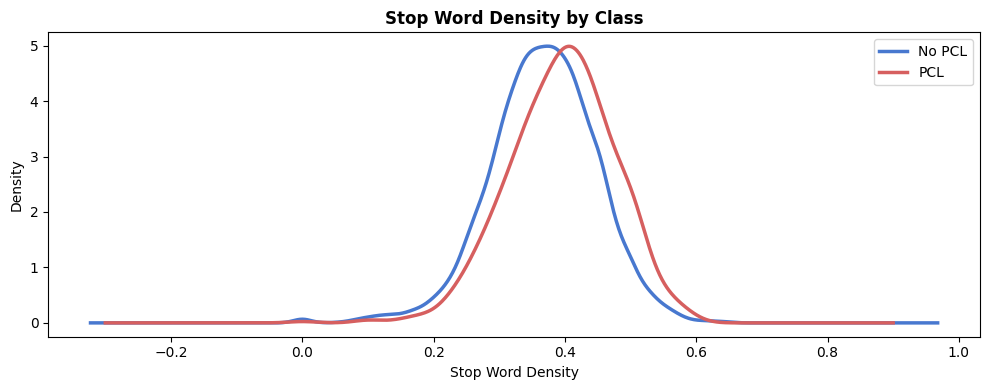

In [ ]:
def stop_density(text):
    tokens = str(text).lower().split()
    if not tokens: return 0
    return sum(1 for t in tokens if t in STOP_WORDS) / len(tokens)

df_train['stop_density'] = df_train['text'].apply(stop_density)

for cls in ['No PCL', 'PCL']:
    d = df_train[df_train['label_str']==cls]['stop_density'].mean()
    print(f'Avg stop word density ({cls}): {d:.3f} ({d*100:.1f}%)')

fig, ax = plt.subplots(figsize=(10, 4))
for cls in ['No PCL', 'PCL']:
    df_train[df_train['label_str']==cls]['stop_density'].plot.kde(
        ax=ax, label=cls, color=PALETTE[cls], linewidth=2.5)
ax.set_xlabel('Stop Word Density'); ax.set_ylabel('Density')
ax.set_title('Stop Word Density by Class', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda7_stop_density.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 8: Word Clouds by Class

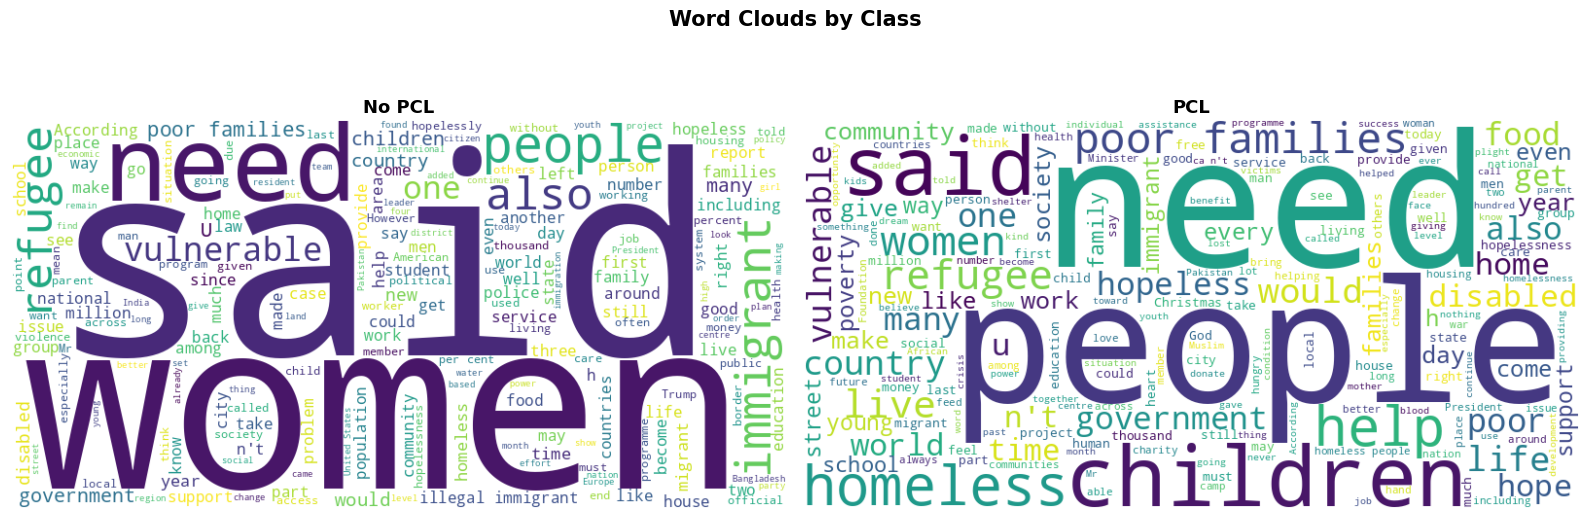

In [ ]:
def plot_wordcloud(text_series, title, ax):
    text_combined = ' '.join(text_series.astype(str))
    wc = WordCloud(width=800, height=400, background_color='white',
                   stopwords=STOP_WORDS).generate(text_combined)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontweight='bold', fontsize=13)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Word Clouds by Class', fontsize=15, fontweight='bold')
plot_wordcloud(df_train[df_train['label_binary']==0]['text'], 'No PCL', axes[0])
plot_wordcloud(df_train[df_train['label_binary']==1]['text'], 'PCL',    axes[1])
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda8_wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 9: POS Density: Adjectives and Verbs

In [ ]:
def get_pos_density(text):
    tokens = nltk.word_tokenize(str(text))
    if not tokens: return 0.0, 0.0
    tags = nltk.pos_tag(tokens)
    adj  = sum(1 for _, t in tags if t.startswith('JJ')) / len(tokens)
    verb = sum(1 for _, t in tags if t.startswith('VB')) / len(tokens)
    return adj, verb

print('Computing POS tags (this takes a few minutes)...')
pos_data = df_train['text'].apply(get_pos_density)
df_train['adj_density']  = [x[0] for x in pos_data]
df_train['verb_density'] = [x[1] for x in pos_data]
print('Done.')

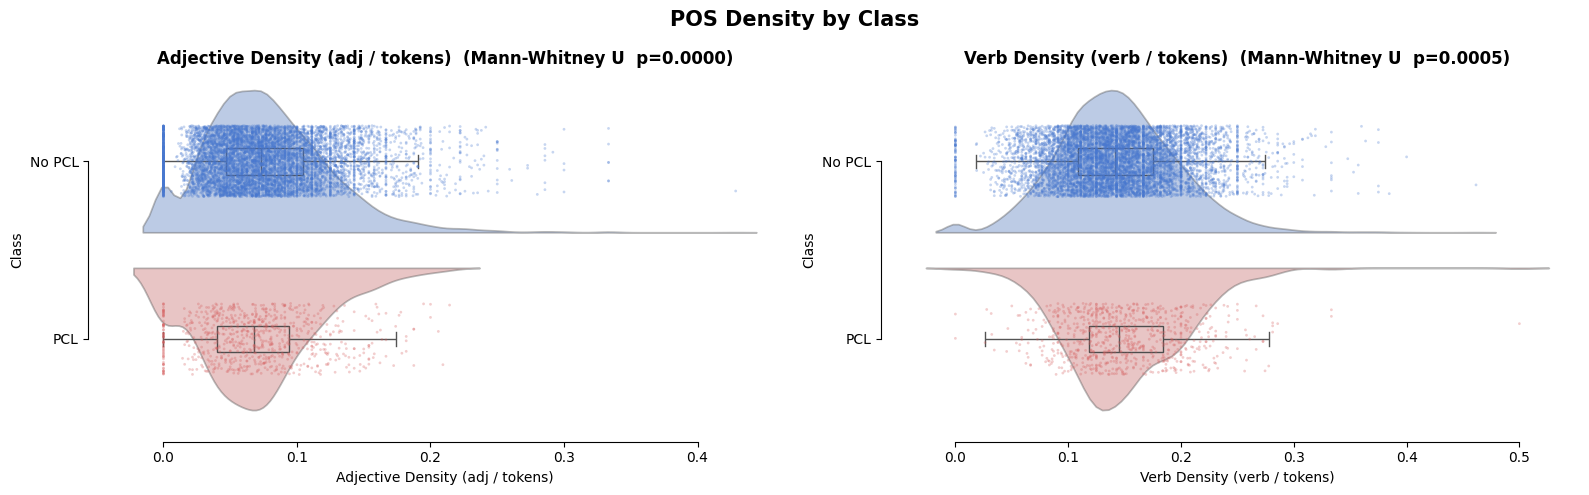

In [ ]:
def raincloud(ax, feature, xlabel):
    g0 = df_train[df_train['label_binary']==0][feature]
    g1 = df_train[df_train['label_binary']==1][feature]
    _, p = mannwhitneyu(g0, g1)
    palette_int = {0: C_NO, 1: C_PCL}
    sns.violinplot(data=df_train, x=feature, y='label_binary', orient='h',
                   hue='label_binary', palette=palette_int,
                   inner=None, split=True, alpha=0.4, ax=ax, legend=False)
    sns.stripplot(data=df_train, x=feature, y='label_binary', orient='h',
                  hue='label_binary', palette=palette_int,
                  size=2, alpha=0.3, jitter=0.2, ax=ax, legend=False)
    sns.boxplot(data=df_train, x=feature, y='label_binary', orient='h',
                hue='label_binary', palette=palette_int,
                width=0.15, showfliers=False,
                boxprops={'facecolor': 'none', 'edgecolor': '0.3'},
                ax=ax, legend=False)
    ax.set_title(f'{xlabel}  (Mann-Whitney U  p={p:.4f})', fontweight='bold')
    ax.set_yticks([0, 1]); ax.set_yticklabels(['No PCL', 'PCL'])
    ax.set_ylabel('Class'); ax.set_xlabel(xlabel)
    sns.despine(trim=True, offset=10, ax=ax)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('POS Density by Class', fontsize=15, fontweight='bold')
raincloud(axes[0], 'adj_density',  'Adjective Density (adj / tokens)')
raincloud(axes[1], 'verb_density', 'Verb Density (verb / tokens)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda9_pos_density.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 10: Named Entity Recognition: Geographic Bias

In [ ]:
# !python -m spacy download en_core_web_sm
nlp = spacy.load('en_core_web_sm')

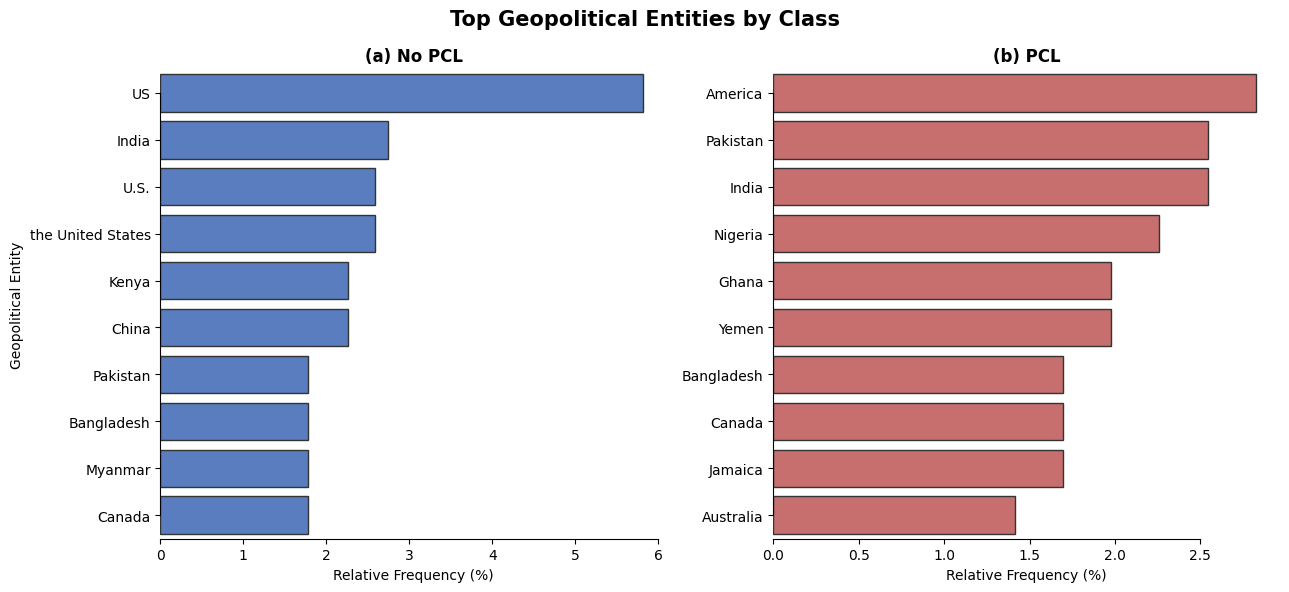

In [ ]:
def get_gpe_df(text_series, n=10):
    sample_text = ' '.join(text_series.sample(min(len(text_series), 1000),
                                               random_state=42).astype(str))
    doc  = nlp(sample_text[:1_000_000])
    gpes = [ent.text.strip() for ent in doc.ents if ent.label_ == 'GPE' and len(ent.text) > 1]
    counts = Counter(gpes).most_common(n)
    df = pd.DataFrame(counts, columns=['Location','Count'])
    df['Percentage'] = df['Count'] / len(gpes) * 100
    return df

df_no_ner  = get_gpe_df(df_train[df_train['label_binary']==0]['text'])
df_pcl_ner = get_gpe_df(df_train[df_train['label_binary']==1]['text'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Top Geopolitical Entities by Class', fontsize=15, fontweight='bold')

sns.barplot(data=df_no_ner,  x='Percentage', y='Location', ax=ax1, color=C_NO,  edgecolor='.2')
ax1.set_title('(a) No PCL', fontweight='bold')
ax1.set_xlabel('Relative Frequency (%)'); ax1.set_ylabel('Geopolitical Entity')

sns.barplot(data=df_pcl_ner, x='Percentage', y='Location', ax=ax2, color=C_PCL, edgecolor='.2')
ax2.set_title('(b) PCL', fontweight='bold')
ax2.set_xlabel('Relative Frequency (%)'); ax2.set_ylabel('')

sns.despine(trim=True)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda10_ner.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 11: PCL Category Distribution

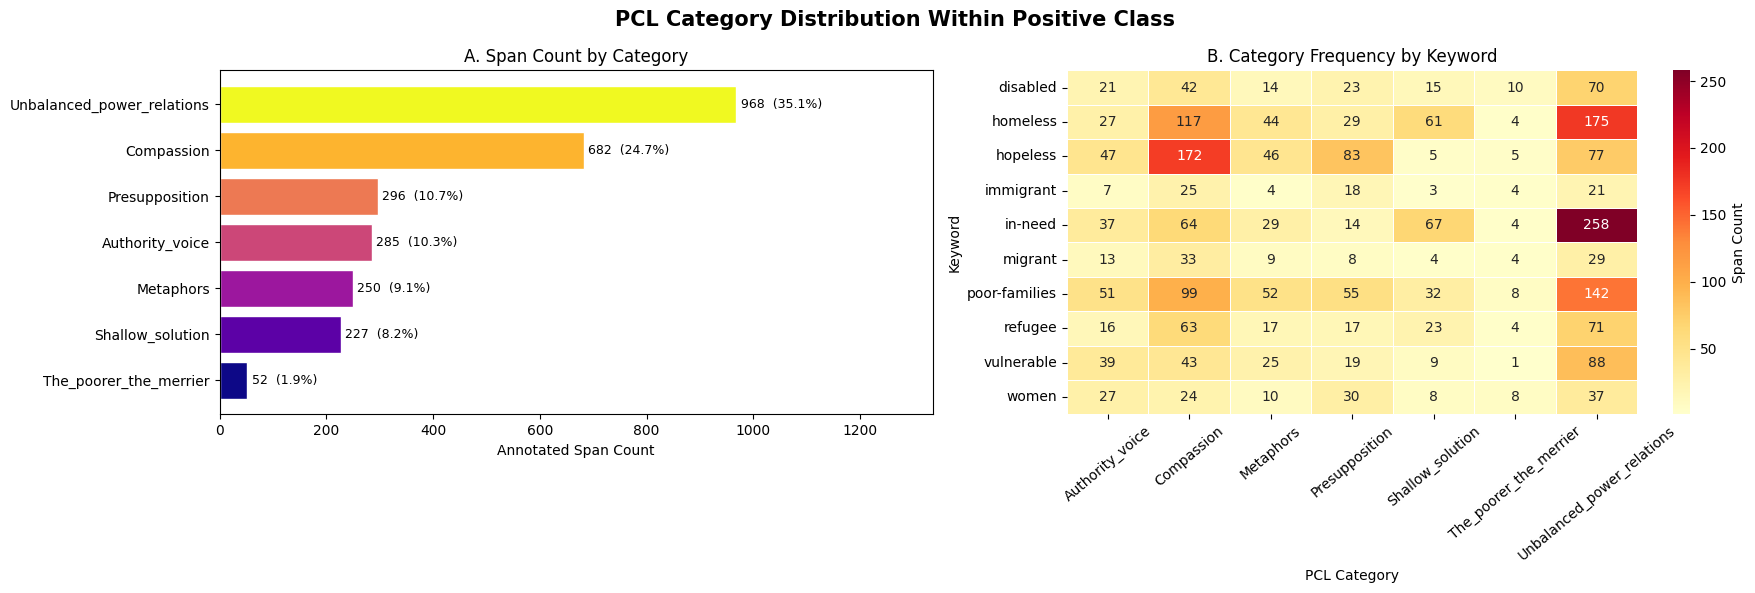

                  category  count       pct
Unbalanced_power_relations    968 35.072464
                Compassion    682 24.710145
            Presupposition    296 10.724638
           Authority_voice    285 10.326087
                 Metaphors    250  9.057971
          Shallow_solution    227  8.224638
    The_poorer_the_merrier     52  1.884058


In [ ]:
cat_counts = df_cat['category'].value_counts().reset_index()
cat_counts.columns = ['category','count']
cat_counts['pct'] = 100 * cat_counts['count'] / cat_counts['count'].sum()
cat_counts = cat_counts.sort_values('count', ascending=True)

pivot_kw = pd.crosstab(df_cat['keyword'], df_cat['category'])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('PCL Category Distribution Within Positive Class',
             fontsize=15, fontweight='bold')

ax = axes[0]
cmap = plt.colormaps['plasma'].resampled(len(cat_counts))
bars = ax.barh(cat_counts['category'], cat_counts['count'],
               color=[cmap(i) for i in range(len(cat_counts))], edgecolor='white')
for bar, val, pct in zip(bars, cat_counts['count'], cat_counts['pct']):
    ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({pct:.1f}%)', va='center', fontsize=9)
ax.set_xlabel('Annotated Span Count')
ax.set_title('A. Span Count by Category')
ax.set_xlim(0, cat_counts['count'].max() * 1.38)

ax = axes[1]
sns.heatmap(pivot_kw, cmap='YlOrRd', annot=True, fmt='d',
            linewidths=0.4, ax=ax, cbar_kws={'label': 'Span Count'})
ax.set_title('B. Category Frequency by Keyword')
ax.set_xlabel('PCL Category'); ax.set_ylabel('Keyword')
ax.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda11_categories.png', dpi=150, bbox_inches='tight')
plt.show()
print(cat_counts[['category','count','pct']].sort_values('count', ascending=False).to_string(index=False))

## EDA 12: Duplicate and Cross-Split Leakage Detection

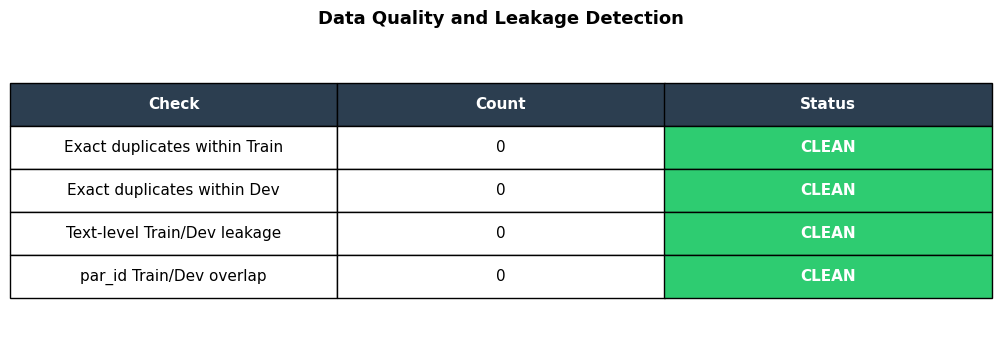

Exact duplicates within Train              0   [CLEAN]
Exact duplicates within Dev                0   [CLEAN]
Text-level Train/Dev leakage               0   [CLEAN]
par_id Train/Dev overlap                   0   [CLEAN]


In [ ]:
train_texts_clean = df_train['text'].str.strip().str.lower()
dev_texts_clean   = df_dev['text'].str.strip().str.lower()

checks = [
    ('Exact duplicates within Train', train_texts_clean.duplicated().sum()),
    ('Exact duplicates within Dev',   dev_texts_clean.duplicated().sum()),
    ('Text-level Train/Dev leakage',  len(set(train_texts_clean) & set(dev_texts_clean))),
    ('par_id Train/Dev overlap',      len(set(df_train['par_id']) & set(df_dev['par_id']))),
]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.axis('off')
ax.set_title('Data Quality and Leakage Detection', fontsize=13, fontweight='bold', pad=20)

tbl = ax.table(
    cellText=[[chk, str(cnt), 'CLEAN' if cnt==0 else 'ACTION REQUIRED'] for chk, cnt in checks],
    colLabels=['Check','Count','Status'],
    cellLoc='center', loc='center'
)
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1.1, 2.5)

for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50'); cell.set_text_props(color='white', fontweight='bold')
    elif c == 2:
        txt = cell.get_text().get_text()
        cell.set_facecolor('#2ecc71' if 'CLEAN' in txt else '#e74c3c')
        cell.set_text_props(color='white', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda12_leakage.png', dpi=150, bbox_inches='tight')
plt.show()

for chk, cnt in checks:
    print(f'{chk:<40} {cnt:>3}   {"[CLEAN]" if cnt==0 else "[ACTION REQUIRED]"}')

## EDA 13: Label Consistency Check

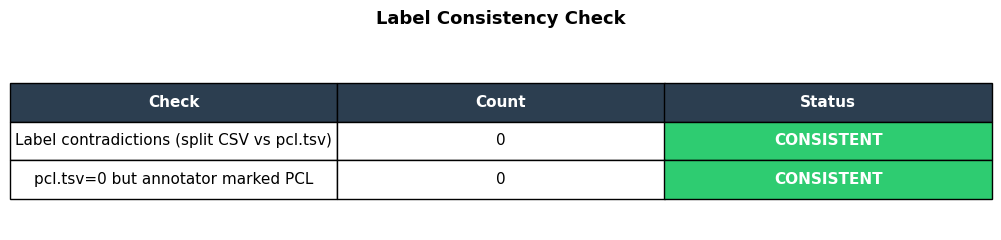

Label contradictions (split CSV vs pcl.tsv)          0   [CONSISTENT]
pcl.tsv=0 but annotator marked PCL                   0   [CONSISTENT]


In [ ]:
# Check binary labels from pcl.tsv agree with the official split CSV labels
train_ids_check = pd.read_csv(TRAIN_SPLIT)
train_ids_check['label_binary_csv'] = train_ids_check['label'].apply(list_to_binary)

merged = train_ids_check[['par_id','label_binary_csv']].merge(
    df_raw[['par_id','label_binary']].rename(columns={'label_binary': 'label_binary_tsv'}),
    on='par_id', how='left'
)
n_contradictions = len(merged[merged['label_binary_csv'] != merged['label_binary_tsv']])

merged2 = train_ids_check[['par_id','label']].merge(
    df_raw[['par_id','label_binary']], on='par_id', how='left')
merged2['label_list'] = merged2['label'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
n_inconsistent = len(merged2[
    (merged2['label_binary'] == 0) &
    (merged2['label_list'].apply(lambda lst: sum(lst) > 0))
])

label_checks = [
    ('Label contradictions (split CSV vs pcl.tsv)', n_contradictions),
    ('pcl.tsv=0 but annotator marked PCL',          n_inconsistent),
]

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis('off')
ax.set_title('Label Consistency Check', fontsize=13, fontweight='bold', pad=20)
tbl = ax.table(
    cellText=[[chk, str(cnt), 'CONSISTENT' if cnt==0 else 'INCONSISTENT']
              for chk, cnt in label_checks],
    colLabels=['Check', 'Count', 'Status'],
    cellLoc='center', loc='center'
)
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1.1, 2.5)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50'); cell.set_text_props(color='white', fontweight='bold')
    elif c == 2:
        txt = cell.get_text().get_text()
        ok  = txt == 'CONSISTENT'
        cell.set_facecolor('#2ecc71' if ok else '#e74c3c')
        cell.set_text_props(color='white', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/label_consistency.png', dpi=150, bbox_inches='tight')
plt.show()
for chk, cnt in label_checks:
    print(f'{chk:<50} {cnt:>3}   {"[CONSISTENT]" if cnt==0 else "[INCONSISTENT]"}')

## EDA 14: HTML Artifacts and Short Text Outliers

In [ ]:
df_train['has_html']     = df_train['text'].str.contains(r'<[^>]+>',    regex=True, na=False)
df_train['has_entities'] = df_train['text'].str.contains(r'&[a-z]+;',  regex=True, na=False)
df_train['has_url']      = df_train['text'].str.contains(r'https?://\S+', regex=True, na=False)

print(f'Rows with HTML tags:     {df_train["has_html"].sum()}')
print(f'Rows with HTML entities: {df_train["has_entities"].sum()}')
print(f'Rows with URLs:          {df_train["has_url"].sum()}')

Rows with HTML tags:     316
Rows with HTML entities: 65
Rows with URLs:          0


In [ ]:
# short texts (< 5 words) are likely captions, not full paragraphs
short_train = df_train[df_train['n_words'] < 5]
dev_nwords  = df_dev['text'].str.split().str.len()
short_dev   = df_dev[dev_nwords < 5]
long_train  = df_train[df_train['n_words'] > 400]

print(f'Short texts (< 5 words)  Train: {len(short_train)},  Dev: {len(short_dev)}')
print(f'Long texts  (> 400 words) Train: {len(long_train)}')
if len(short_train) > 0:
    print(short_train[['par_id','text','label_binary']].to_string(index=False))

Short texts (< 5 words)  Train: 11,  Dev: 2
Long texts  (> 400 words) Train: 3
 par_id                              text  label_binary
    318            The Filipino immigrant             0
   1434 Volunteer helps earliest refugees             0
   1595             UTI in pregnant women             0
   1657                          refugees             0
   1955                Review refugee law             0
   3121          *Fighting over men/women             0
   4257   Germans investigate 59 refugees             0
   4457 Landslide leaves postman homeless             0
   5132             Focus on the homeless             0
   6021              Pretty much hopeless             0
   6739   Repatriation of Afghan refugees             0


In [ ]:
# text cleaning function for use in the Stage 4 preprocessing pipeline
def clean_pcl_text(text):
    text = str(text)
    text = html.unescape(text)                       # &amp; -> &
    text = re.sub(r'<[^>]+>', ' ', text)            # strip HTML tags
    text = re.sub(r'https?://\S+', '[URL]', text)   # mask URLs
    text = re.sub(r'@@\w+', '[USER]', text)         # mask @-handles
    text = re.sub(r" n't", "n't", text)             # repair tokeniser artefacts
    text = re.sub(r" 's", "'s", text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_train['text_clean'] = df_train['text'].apply(clean_pcl_text)
df_dev['text_clean']   = df_dev['text'].apply(clean_pcl_text)

print(f'Remaining HTML tags after cleaning:     {df_train["text_clean"].str.contains(r"<[^>]+>", regex=True).sum()}')
print(f'Remaining HTML entities after cleaning: {df_train["text_clean"].str.contains(r"&[a-z]+;", regex=True).sum()}')

Remaining HTML tags after cleaning:     0
Remaining HTML entities after cleaning: 0


## EDA 15: t-SNE Embedding Visualisation

Generating RoBERTa embeddings...
Running t-SNE...


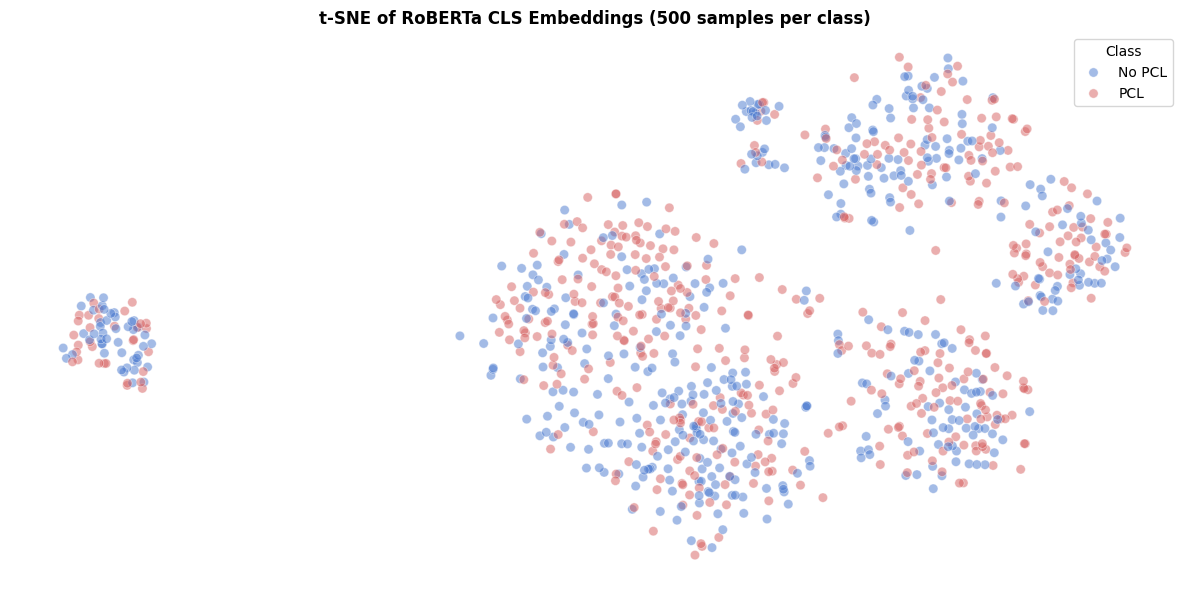

In [ ]:
import os
import logging
logging.getLogger('transformers').setLevel(logging.ERROR)

device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tokenizer = AutoTokenizer.from_pretrained('roberta-large', token=os.environ.get('HF_TOKEN'))
emb_model = AutoModel.from_pretrained(
    'roberta-large',
    token=os.environ.get('HF_TOKEN'),
    ignore_mismatched_sizes=True
).to(device)

def get_embeddings(text_list, batch_size=16):
    emb_model.eval()
    embeddings = []
    for i in range(0, len(text_list), batch_size):
        batch  = text_list[i:i+batch_size]
        inputs = tokenizer(batch, padding=True, truncation=True,
                           max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            out = emb_model(**inputs)
            embeddings.append(out.last_hidden_state[:, 0, :].cpu().numpy())  # CLS token
    return np.vstack(embeddings)

n_samples  = 500
subset_pcl = df_train[df_train['label_binary']==1].sample(n=n_samples, random_state=1)
subset_no  = df_train[df_train['label_binary']==0].sample(n=n_samples, random_state=1)
subset     = pd.concat([subset_pcl, subset_no]).sample(frac=1, random_state=1)

print('Generating RoBERTa embeddings...')
X_emb = get_embeddings(subset['text'].tolist())
print('Running t-SNE...')
X_2d  = TSNE(n_components=2, random_state=1, perplexity=30,
             init='pca', learning_rate='auto').fit_transform(X_emb)

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(x=X_2d[:,0], y=X_2d[:,1],
                hue=subset['label_binary'].map({0: 'No PCL', 1: 'PCL'}),
                palette=PALETTE, alpha=0.5, s=45, edgecolor='w', linewidth=0.5, ax=ax)
ax.set_xticks([]); ax.set_yticks([])
sns.despine(left=True, bottom=True)
ax.set_title('t-SNE of RoBERTa CLS Embeddings (500 samples per class)', fontweight='bold')
ax.legend(title='Class', loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda15_tsne.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 15b: UMAP Embedding Visualisation

Running UMAP on the same embeddings...


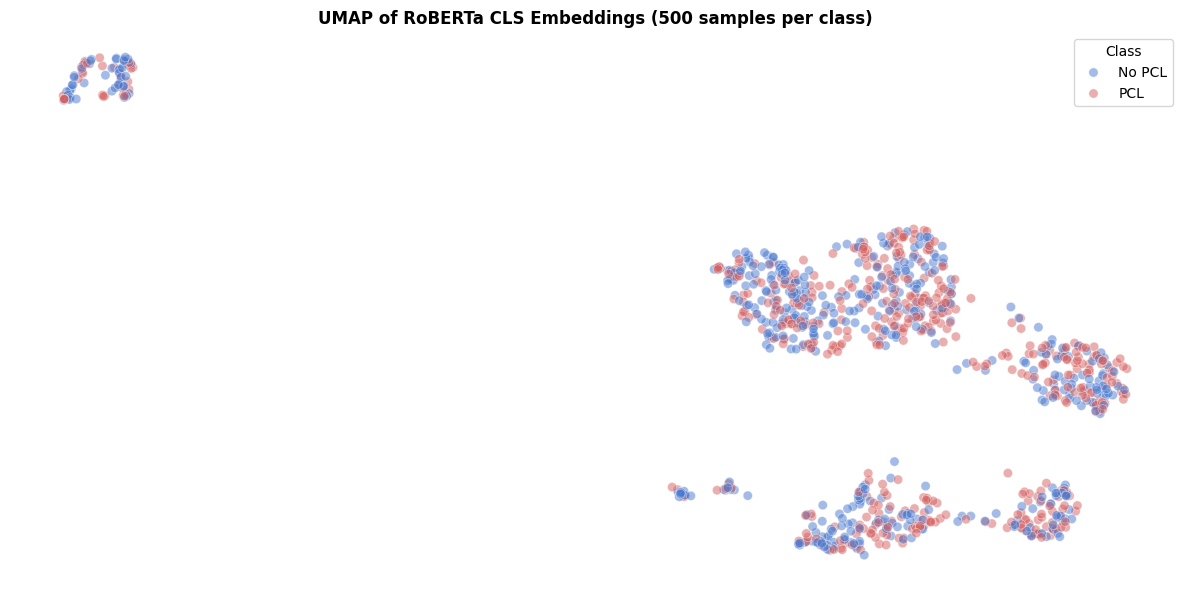

In [ ]:
print('Running UMAP on the same embeddings...')
reducer  = umap.UMAP(n_components=2, random_state=42)
X_umap   = reducer.fit_transform(X_emb)

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1],
                hue=subset['label_binary'].map({0: 'No PCL', 1: 'PCL'}),
                palette=PALETTE, alpha=0.5, s=45,
                edgecolor='w', linewidth=0.5, ax=ax)
ax.set_xticks([]); ax.set_yticks([])
sns.despine(left=True, bottom=True)
ax.set_title('UMAP of RoBERTa CLS Embeddings (500 samples per class)', fontweight='bold')
ax.legend(title='Class', loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda15b_umap.png', dpi=150, bbox_inches='tight')
plt.show()

## EDA 16: LDA Topic Modelling

In [ ]:
N_TOPICS    = 5
N_TOP_WORDS = 10
RS          = 42

def fit_lda(texts):
    vec = CountVectorizer(max_features=3000, min_df=5,
                          stop_words='english', ngram_range=(1, 2))
    dtm = vec.fit_transform(texts)
    lda = LatentDirichletAllocation(n_components=N_TOPICS, max_iter=30,
                                     learning_method='batch', random_state=RS, n_jobs=-1)
    lda.fit(dtm)
    return lda, dtm, vec.get_feature_names_out()

pcl_raw = df_train[df_train['label_binary']==1]['text'].tolist()
no_raw  = df_train[df_train['label_binary']==0]['text'].tolist()

print(f'Fitting LDA on {len(pcl_raw):,} PCL texts...')
lda_pcl, dtm_pcl, vocab_pcl = fit_lda(pcl_raw)
print(f'Fitting LDA on {len(no_raw):,} No-PCL texts...')
lda_no,  dtm_no,  vocab_no  = fit_lda(no_raw)
print('Done.')

Fitting LDA on 794 PCL texts...
Fitting LDA on 7,581 No-PCL texts...
Done.


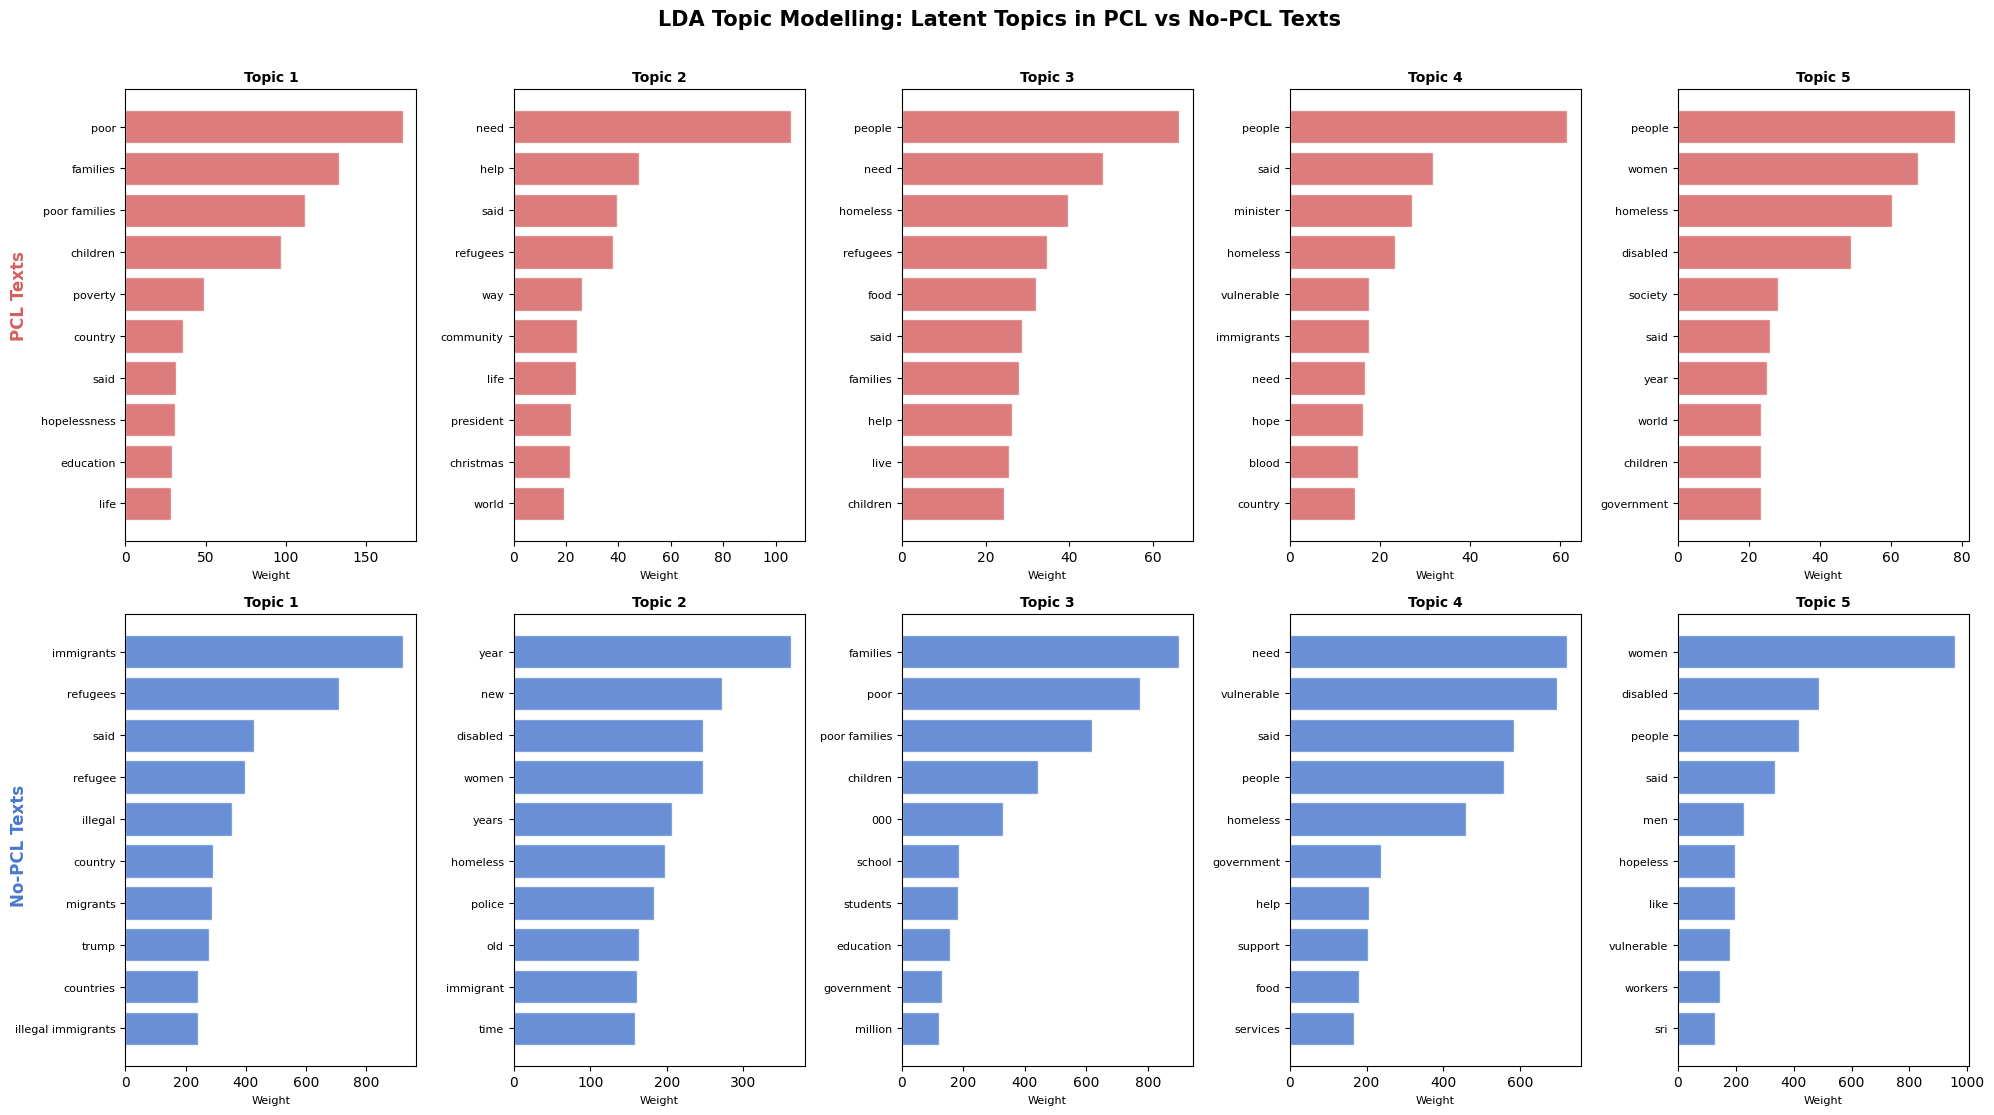

PCL topics:
  1: poor | families | poor families | children | poverty | country | said | hopelessness
  2: need | help | said | refugees | way | community | life | president
  3: people | need | homeless | refugees | food | said | families | help
  4: people | said | minister | homeless | vulnerable | immigrants | need | hope
  5: people | women | homeless | disabled | society | said | year | world

No-PCL topics:
  1: immigrants | refugees | said | refugee | illegal | country | migrants | trump
  2: year | new | disabled | women | years | homeless | police | old
  3: families | poor | poor families | children | 000 | school | students | education
  4: need | vulnerable | said | people | homeless | government | help | support
  5: women | disabled | people | said | men | hopeless | like | vulnerable



In [ ]:
def top_words(lda, vocab, n=N_TOP_WORDS):
    return [[vocab[i] for i in comp.argsort()[-n:][::-1]] for comp in lda.components_]

topics_pcl = top_words(lda_pcl, vocab_pcl)
topics_no  = top_words(lda_no,  vocab_no)

def plot_lda_row(lda, vocab, colour, axes_row):
    for t_idx, ax in enumerate(axes_row):
        weights = lda.components_[t_idx]
        top_idx = weights.argsort()[-N_TOP_WORDS:][::-1]
        tw = [vocab[i] for i in top_idx]; tv = [weights[i] for i in top_idx]
        ax.barh(range(N_TOP_WORDS), tv[::-1], color=colour, alpha=0.82, edgecolor='white')
        ax.set_yticks(range(N_TOP_WORDS)); ax.set_yticklabels(tw[::-1], fontsize=8)
        ax.set_title(f'Topic {t_idx+1}', fontsize=10, fontweight='bold')
        ax.set_xlabel('Weight', fontsize=8)

fig, axes = plt.subplots(2, N_TOPICS, figsize=(20, 11))
fig.suptitle('LDA Topic Modelling: Latent Topics in PCL vs No-PCL Texts',
             fontsize=15, fontweight='bold', y=1.01)
for row, (label, colour) in enumerate([('PCL Texts', C_PCL), ('No-PCL Texts', C_NO)]):
    fig.text(0.005, 0.75 - row*0.5, label, va='center', ha='left',
             fontsize=12, fontweight='bold', color=colour, rotation=90)
plot_lda_row(lda_pcl, vocab_pcl, C_PCL, axes[0])
plot_lda_row(lda_no,  vocab_no,  C_NO,  axes[1])
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda16_lda_topics.png', dpi=150, bbox_inches='tight')
plt.show()

for label, topics in [('PCL', topics_pcl), ('No-PCL', topics_no)]:
    print(f'{label} topics:')
    for i, tw in enumerate(topics):
        print(f'  {i+1}: {" | ".join(tw[:8])}')
    print()

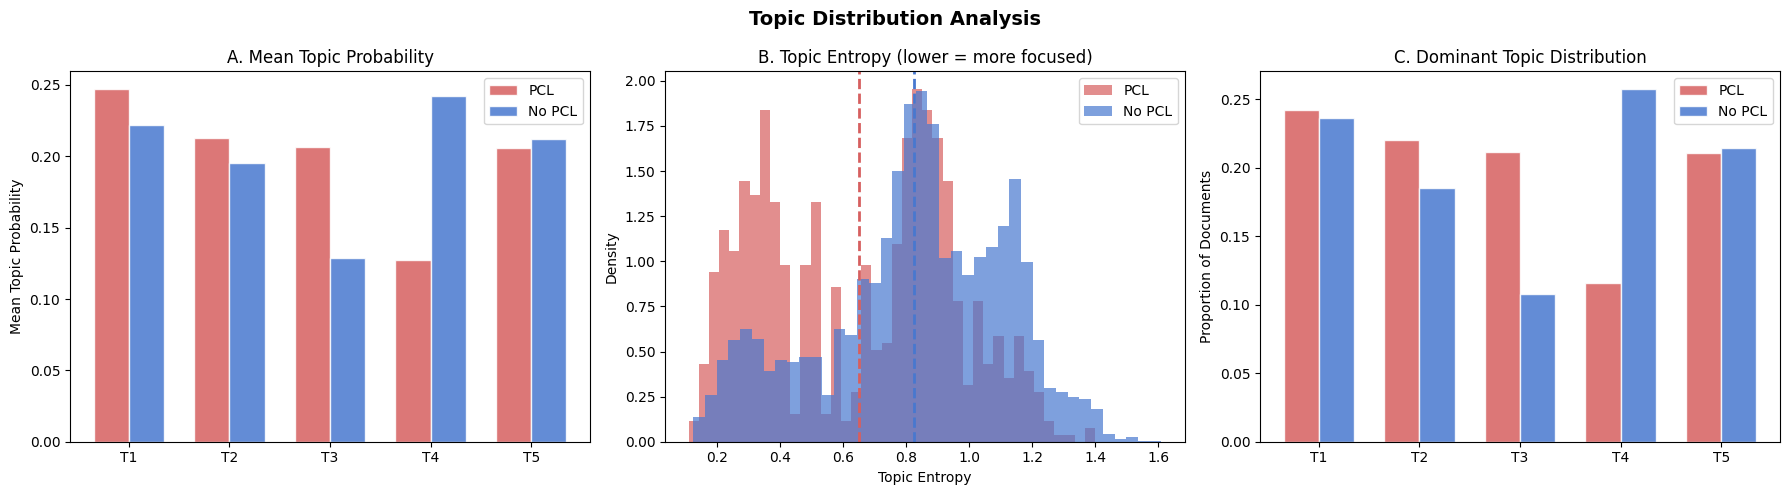

Mean topic entropy  PCL:    0.650
Mean topic entropy  No PCL: 0.824


In [ ]:
doc_topics_pcl = lda_pcl.transform(dtm_pcl)
doc_topics_no  = lda_no.transform(dtm_no)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Topic Distribution Analysis', fontsize=14, fontweight='bold')

x = np.arange(N_TOPICS); w = 0.35
ax = axes[0]
ax.bar(x - w/2, doc_topics_pcl.mean(axis=0), w, color=C_PCL, alpha=0.85, label='PCL', edgecolor='white')
ax.bar(x + w/2, doc_topics_no.mean(axis=0),  w, color=C_NO,  alpha=0.85, label='No PCL', edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([f'T{i+1}' for i in range(N_TOPICS)])
ax.set_ylabel('Mean Topic Probability'); ax.set_title('A. Mean Topic Probability')
ax.legend()

ax = axes[1]
def entropy(p):
    p = p + 1e-12
    return -np.sum(p * np.log(p), axis=1)
ent_pcl = entropy(doc_topics_pcl)
ent_no  = entropy(doc_topics_no)
ax.hist(ent_pcl, bins=40, color=C_PCL, alpha=0.7, label='PCL',    density=True)
ax.hist(ent_no,  bins=40, color=C_NO,  alpha=0.7, label='No PCL', density=True)
ax.axvline(ent_pcl.mean(), color=C_PCL, linestyle='--', linewidth=2)
ax.axvline(ent_no.mean(),  color=C_NO,  linestyle='--', linewidth=2)
ax.set_xlabel('Topic Entropy'); ax.set_ylabel('Density')
ax.set_title('B. Topic Entropy (lower = more focused)')
ax.legend()

ax = axes[2]
dom_pcl = np.argmax(doc_topics_pcl, axis=1)
dom_no  = np.argmax(doc_topics_no,  axis=1)
ax.bar(x - w/2, np.bincount(dom_pcl, minlength=N_TOPICS)/len(dom_pcl),
       w, color=C_PCL, alpha=0.85, label='PCL', edgecolor='white')
ax.bar(x + w/2, np.bincount(dom_no,  minlength=N_TOPICS)/len(dom_no),
       w, color=C_NO,  alpha=0.85, label='No PCL', edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([f'T{i+1}' for i in range(N_TOPICS)])
ax.set_ylabel('Proportion of Documents'); ax.set_title('C. Dominant Topic Distribution')
ax.legend()

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda16b_topic_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Mean topic entropy  PCL:    {ent_pcl.mean():.3f}')
print(f'Mean topic entropy  No PCL: {ent_no.mean():.3f}')